# Overfitting vs Underfitting 

## 1.Initial model

In [1]:
import tensorflow as tf 
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Flatten , Dense 
from tensorflow.keras.callbacks  import EarlyStopping

In [3]:
# load training and testing data 
(x_train , y_train), (x_test , y_test)= mnist.load_data()

def create_model():
    model = Sequential([
        Flatten(input_shape=(28 , 28 )),
        Dense(128 , activation="relu"),
        Dense(10 , activation="softmax")

    ])

    model.compile(optimizer ='adam' ,
                  loss = "sparse_categorical_crossentropy",
                  metrics = ['accuracy']) 
    return model

model = create_model()

# train baseline model for 10 epochs with 20% validation data
history_baseline = model.fit(x_train , y_train , epochs = 10 , validation_split = 0.2 , verbose = 1 )

/home/saagar101/tf_env/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
W0000 00:00:1778031896.957945    1889 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1778031896.963879    1889 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1778031897.248769    1889 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5174 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5050 Laptop GPU, pci bus id: 0000:01:00.0, com

Epoch 1/10


I0000 00:00:1778031899.611628    3898 service.cc:153] XLA service 0x7ed65c02f200 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778031899.611706    3898 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5050 Laptop GPU, Compute Capability 12.0a (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.0)
I0000 00:00:1778031899.665147    3898 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1778031899.825432    3898 cuda_dnn.cc:461] Loaded cuDNN version 92100
I0000 00:00:1778031899.843521    3898 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_921__.12
I0000 00:00:1778031901.633770    3985 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 12 bytes spill stores, 12 bytes spill loads



  25/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.2627 - loss: 83.9214  

I0000 00:00:1778031904.130245    3898 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.8547 - loss: 3.3545 - val_accuracy: 0.8861 - val_loss: 0.5343
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9066 - loss: 0.4244 - val_accuracy: 0.9204 - val_loss: 0.4066
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9268 - loss: 0.3106 - val_accuracy: 0.9225 - val_loss: 0.3681
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9348 - loss: 0.2640 - val_accuracy: 0.9293 - val_loss: 0.3023
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9400 - loss: 0.2354 - val_accuracy: 0.9350 - val_loss: 0.2936
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9446 - loss: 0.2205 - val_accuracy: 0.9438 - val_loss: 0.2557
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9494 - loss: 0.1998 - val_accuracy: 0.9420 - val_loss: 0.2494
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9505 - loss: 0.1960 - val_

## 2. Run model on Normalized Data

Epoch 1/10


I0000 00:00:1778032173.684243    3899 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_77288__.12
I0000 00:00:1778032174.385583    5427 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 12 bytes spill stores, 12 bytes spill loads



1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9155 - loss: 0.2952 - val_accuracy: 0.9525 - val_loss: 0.1662
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9612 - loss: 0.1309 - val_accuracy: 0.9638 - val_loss: 0.1221
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9738 - loss: 0.0882 - val_accuracy: 0.9712 - val_loss: 0.1011
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9810 - loss: 0.0650 - val_accuracy: 0.9720 - val_loss: 0.0990
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 36s 24ms/step - accuracy: 0.9841 - loss: 0.0514 - val_accuracy: 0.9719 - val_loss: 0.0953
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 36s 24ms/step - accuracy: 0.9886 - loss: 0.0386 - val_accuracy: 0.9766 - val_loss: 0.0820
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.9912 - loss: 0.0299 - val_accuracy: 0.9709 - val_loss: 0.0981
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9915 - loss: 0.0263 -

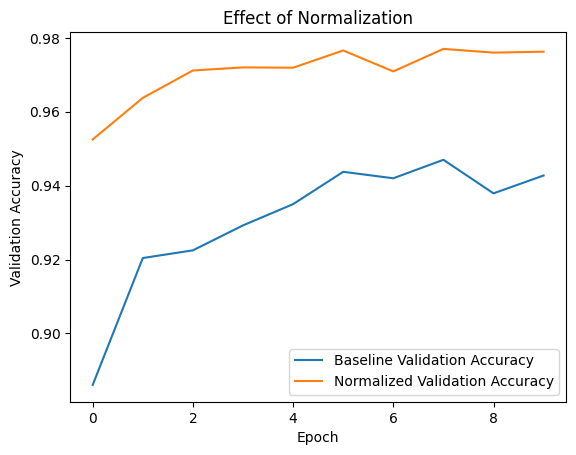

CPU times: user 2min 39s, sys: 45.7 s, total: 3min 25s
Wall time: 3min 13s


In [4]:
%%time
# laod and normalize the data
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

# Define a model for normalized data
def create_model_with_norm_data():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model_with_norm_data = create_model_with_norm_data()

# Train the baseline model
history_norm_data = model_with_norm_data.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=1)

# plot the effect of normalization
plt.plot(history_baseline.history['val_accuracy'], label='Baseline Validation Accuracy')
plt.plot(history_norm_data.history['val_accuracy'], label = 'Normalized Validation Accuracy')
plt.title('Effect of Normalization')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend(loc='lower right')
plt.show()

## 3. Adding Dropout
Now, let's modify the model to include dropout and observe its effect.

Epoch 1/10


I0000 00:00:1778032451.710078    3900 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_153732__.13


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8720 - loss: 0.4374 - val_accuracy: 0.9484 - val_loss: 0.1812
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.9290 - loss: 0.2426 - val_accuracy: 0.9597 - val_loss: 0.1408
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9392 - loss: 0.2022 - val_accuracy: 0.9647 - val_loss: 0.1240
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9478 - loss: 0.1741 - val_accuracy: 0.9677 - val_loss: 0.1145
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9525 - loss: 0.1543 - val_accuracy: 0.9688 - val_loss: 0.1055
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9556 - loss: 0.1470 - val_accuracy: 0.9728 - val_loss: 0.0966
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.9585 - loss: 0.1368 - val_accuracy: 0.9718 - val_loss: 0.0937
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9593 - loss: 0.1310 - va

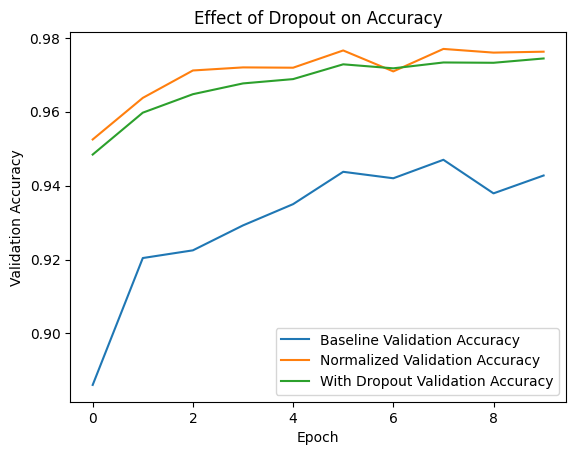

In [5]:
# Define a model with dropout
def create_model_with_dropout():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.5),  # Adding dropout
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model_with_dropout = create_model_with_dropout()

# Train the model with dropout
history_dropout = model_with_dropout.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=1)

# Plotting the effect of dropout
plt.plot(history_baseline.history['val_accuracy'], label='Baseline Validation Accuracy')
# plot line for normalized data
plt.plot(history_norm_data.history['val_accuracy'], label='Normalized Validation Accuracy')
plt.plot(history_dropout.history['val_accuracy'], label='With Dropout Validation Accuracy')
plt.title('Effect of Dropout on Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()


## 4. Early Stopping
Finally, we will use early stopping to stop training when the validation loss starts to increase.

Epoch 1/10


I0000 00:00:1778032677.272307    3899 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_230100__.12


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9186 - loss: 0.2850 - val_accuracy: 0.9551 - val_loss: 0.1507
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9632 - loss: 0.1263 - val_accuracy: 0.9672 - val_loss: 0.1134
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9742 - loss: 0.0866 - val_accuracy: 0.9705 - val_loss: 0.1021
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9814 - loss: 0.0637 - val_accuracy: 0.9725 - val_loss: 0.0923
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9852 - loss: 0.0495 - val_accuracy: 0.9704 - val_loss: 0.1020
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9889 - loss: 0.0372 - val_accuracy: 0.9728 - val_loss: 0.0953
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9911 - loss: 0.0301 - val_accuracy: 0.9743 - val_loss: 0.0967


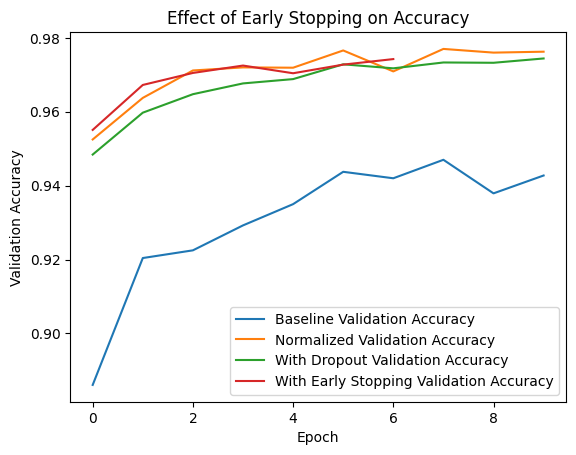

In [6]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3)

model_with_es = create_model_with_norm_data()

# train with early stop
history_es = model_with_es.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=1, callbacks=[early_stopping])

# plot the effect of early stopping
plt.plot(history_baseline.history['val_accuracy'], label='Baseline Validation Accuracy')
# plot line for normalized data
plt.plot(history_norm_data.history['val_accuracy'], label='Normalized Validation Accuracy')
plt.plot(history_dropout.history['val_accuracy'], label='With Dropout Validation Accuracy')
plt.plot(history_es.history['val_accuracy'], label='With Early Stopping Validation Accuracy')
plt.title('Effect of Early Stopping on Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

## 5. L1/L2 Regularization

L1 and L2 are widely used regularization methods that help prevent overfitting by adding a penalty to the model’s loss function.

**In Keras:**

* L1: `kernel_regularizer=regularizers.l1(0.001)`
* L2: `kernel_regularizer=regularizers.l2(0.001)`

L1 regularization adds the sum of absolute weight values to the loss, while L2 adds the sum of squared weight values.

* **L1:** pushes some weights exactly to zero (feature selection)
* **L2:** reduces weight values, keeping them small but non-zero


Epoch 1/10


I0000 00:00:1778032936.977539    3896 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_284059__.15


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 46s 28ms/step - accuracy: 0.8670 - loss: 0.6562 - val_accuracy: 0.9450 - val_loss: 0.3862
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 33s 22ms/step - accuracy: 0.9212 - loss: 0.4488 - val_accuracy: 0.9537 - val_loss: 0.3328
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.9313 - loss: 0.4033 - val_accuracy: 0.9584 - val_loss: 0.3070
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9357 - loss: 0.3813 - val_accuracy: 0.9622 - val_loss: 0.2891
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9414 - loss: 0.3669 - val_accuracy: 0.9642 - val_loss: 0.2860
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9415 - loss: 0.3585 - val_accuracy: 0.9682 - val_loss: 0.2752
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9431 - loss: 0.3551 - val_accuracy: 0.9668 - val_loss: 0.2751
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9442 - loss: 0.34

I0000 00:00:1778033171.064986    3898 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_360594__.15


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - accuracy: 0.8730 - loss: 0.4546 - val_accuracy: 0.9482 - val_loss: 0.2137
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9273 - loss: 0.2756 - val_accuracy: 0.9612 - val_loss: 0.1691
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9394 - loss: 0.2407 - val_accuracy: 0.9647 - val_loss: 0.1544
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9445 - loss: 0.2217 - val_accuracy: 0.9671 - val_loss: 0.1502
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9489 - loss: 0.2094 - val_accuracy: 0.9693 - val_loss: 0.1429
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9504 - loss: 0.2055 - val_accuracy: 0.9719 - val_loss: 0.1399
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9518 - loss: 0.2012 - val_accuracy: 0.9710 - val_loss: 0.1405
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9542 - loss: 0.19

I0000 00:00:1778033340.105769    3900 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_437164__.16


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.8694 - loss: 0.6590 - val_accuracy: 0.9463 - val_loss: 0.3822
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9200 - loss: 0.4563 - val_accuracy: 0.9565 - val_loss: 0.3286
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9299 - loss: 0.4096 - val_accuracy: 0.9615 - val_loss: 0.3140
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9356 - loss: 0.3861 - val_accuracy: 0.9624 - val_loss: 0.2902
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9378 - loss: 0.3743 - val_accuracy: 0.9659 - val_loss: 0.2846
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9403 - loss: 0.3654 - val_accuracy: 0.9668 - val_loss: 0.2794
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9413 - loss: 0.3596 - val_accuracy: 0.9664 - val_loss: 0.2821
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9443 - loss: 0.35

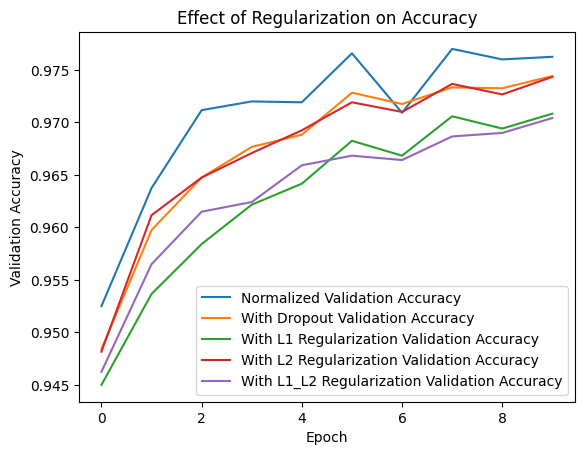

In [7]:
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import l1, l2, l1_l2
import matplotlib.pyplot as plt

# Define a model with L1 regularization
def create_model_with_l1():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu', kernel_regularizer=l1(0.0001)),  # L1 regularization
        Dropout(0.5), # Adding dropout which will also be regularized by L1
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Define a model with L2 regularization
def create_model_with_l2():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu', kernel_regularizer=l2(0.0001)),  # L2 regularization
        Dropout(0.5), # Adding dropout which will also be regularized by L2
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# should we combine them both?
# Define a model with L1_L2 (combined) regularization
def create_model_with_l1_l2():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu', kernel_regularizer=l1_l2(l1=0.0001, l2=0.0001)),  # L1_L2 regularization
        Dropout(0.5), # Adding dropout which will also be regularized by L1_L2
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Prepare and train the models
model_with_l1 = create_model_with_l1()
history_l1 = model_with_l1.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=1)

model_with_l2 = create_model_with_l2()
history_l2 = model_with_l2.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=1)

model_with_l1_l2 = create_model_with_l1_l2()
history_l1_l2 = model_with_l1_l2.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=1)

# Plotting the effect of regularization
# plot line for normalized data
plt.plot(history_norm_data.history['val_accuracy'], label='Normalized Validation Accuracy')
plt.plot(history_dropout.history['val_accuracy'], label='With Dropout Validation Accuracy')
plt.plot(history_l1.history['val_accuracy'], label='With L1 Regularization Validation Accuracy')
plt.plot(history_l2.history['val_accuracy'], label='With L2 Regularization Validation Accuracy')
plt.plot(history_l1_l2.history['val_accuracy'], label='With L1_L2 Regularization Validation Accuracy')
plt.title('Effect of Regularization on Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

## 6. K-Fold Cross-Validation

**K-fold cross-validation in TensorFlow** is not built-in like in some other libraries (e.g., scikit-learn), so it needs to be implemented manually.

In TensorFlow, you perform k-fold cross-validation by splitting your dataset into *k* equal parts (folds), then repeatedly training the model on *k−1* folds and testing it on the remaining fold.

The following example shows how to apply k-fold cross-validation on the MNIST dataset using a simple neural network model similar to the previous ones.


In [ ]:
 
from sklearn.model_selection import KFold
from tensorflow.keras.utils import to_categorical

# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize data
x_train, x_test = x_train / 255.0, x_test / 255.0

# One-hot encode labels
y_train = to_categorical(y_train, 10)

# Define model
def create_model():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# K-Fold setup
k = 5
kf = KFold(n_splits=k, shuffle=True)

scores = []

# K-Fold loop
for fold, (train_index, val_index) in enumerate(kf.split(x_train), 1):
    print(f"\nTraining Fold {fold}...")
    
    x_train_fold, x_val_fold = x_train[train_index], x_train[val_index]
    y_train_fold, y_val_fold = y_train[train_index], y_train[val_index]
    
    model = create_model()
    
    history = model.fit(
        x_train_fold, y_train_fold,
        epochs=10,
        validation_data=(x_val_fold, y_val_fold),
        verbose=1
    )
    
    val_loss = history.history['val_loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    
    scores.append((val_loss, val_acc))




Training Fold 1...
Epoch 1/10


I0000 00:00:1778033730.593689    3899 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_513659__.16


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 38s 23ms/step - accuracy: 0.9201 - loss: 0.2801 - val_accuracy: 0.9532 - val_loss: 0.1589
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9623 - loss: 0.1249 - val_accuracy: 0.9661 - val_loss: 0.1134
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9752 - loss: 0.0845 - val_accuracy: 0.9674 - val_loss: 0.1035
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9814 - loss: 0.0622 - val_accuracy: 0.9703 - val_loss: 0.1001
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9854 - loss: 0.0482 - val_accuracy: 0.9741 - val_loss: 0.0842
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9886 - loss: 0.0380 - val_accuracy: 0.9693 - val_loss: 0.0988
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9909 - loss: 0.0302 - val_accuracy: 0.9706 - val_loss: 0.0974
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9930 - loss: 0.02

I0000 00:00:1778033913.815821    3899 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_590160__.16


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9201 - loss: 0.2836 - val_accuracy: 0.9541 - val_loss: 0.1543
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 33s 22ms/step - accuracy: 0.9635 - loss: 0.1247 - val_accuracy: 0.9668 - val_loss: 0.1140
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 54s 36ms/step - accuracy: 0.9753 - loss: 0.0844 - val_accuracy: 0.9692 - val_loss: 0.1050
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 54s 36ms/step - accuracy: 0.9809 - loss: 0.0629 - val_accuracy: 0.9722 - val_loss: 0.0917
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 47s 32ms/step - accuracy: 0.9852 - loss: 0.0485 - val_accuracy: 0.9732 - val_loss: 0.0910
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.9893 - loss: 0.0368 - val_accuracy: 0.9732 - val_loss: 0.0909
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9911 - loss: 0.0294 - val_accuracy: 0.9730 - val_loss: 0.0945
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9935 - loss: 0.02

I0000 00:00:1778034246.497528    3897 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_666661__.16


... (2 outputs left out)

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 17ms/step - accuracy: 0.9209 - loss: 0.2814 - val_accuracy: 0.9526 - val_loss: 0.1593
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.9625 - loss: 0.1268 - val_accuracy: 0.9640 - val_loss: 0.1195
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9746 - loss: 0.0863 - val_accuracy: 0.9697 - val_loss: 0.0968
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9810 - loss: 0.0633 - val_accuracy: 0.9726 - val_loss: 0.0912
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9855 - loss: 0.0480 - val_accuracy: 0.9767 - val_loss: 0.0808
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9885 - loss: 0.0373 - val_accuracy: 0.9728 - val_loss: 0.0902
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9916 - loss: 0.0291 - val_accuracy: 0.9768 - val_loss: 0.0837
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9926 - loss: 0.0247 - val_ac

I0000 00:00:1778034619.112206    3899 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_819663__.16


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9193 - loss: 0.2853 - val_accuracy: 0.9502 - val_loss: 0.1648
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9618 - loss: 0.1294 - val_accuracy: 0.9635 - val_loss: 0.1206
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9737 - loss: 0.0895 - val_accuracy: 0.9685 - val_loss: 0.1086
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9799 - loss: 0.0659 - val_accuracy: 0.9737 - val_loss: 0.0851
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9846 - loss: 0.0510 - val_accuracy: 0.9754 - val_loss: 0.0820
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9873 - loss: 0.0409 - val_accuracy: 0.9757 - val_loss: 0.0797
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9910 - loss: 0.0302 - val_accuracy: 0.9747 - val_loss: 0.0881
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9920 - loss: 0.0251 - val_accurac

NameError: name 'np' is not defined


K-Fold Results:
Average Loss: 0.0907
Average Accuracy: 0.9765


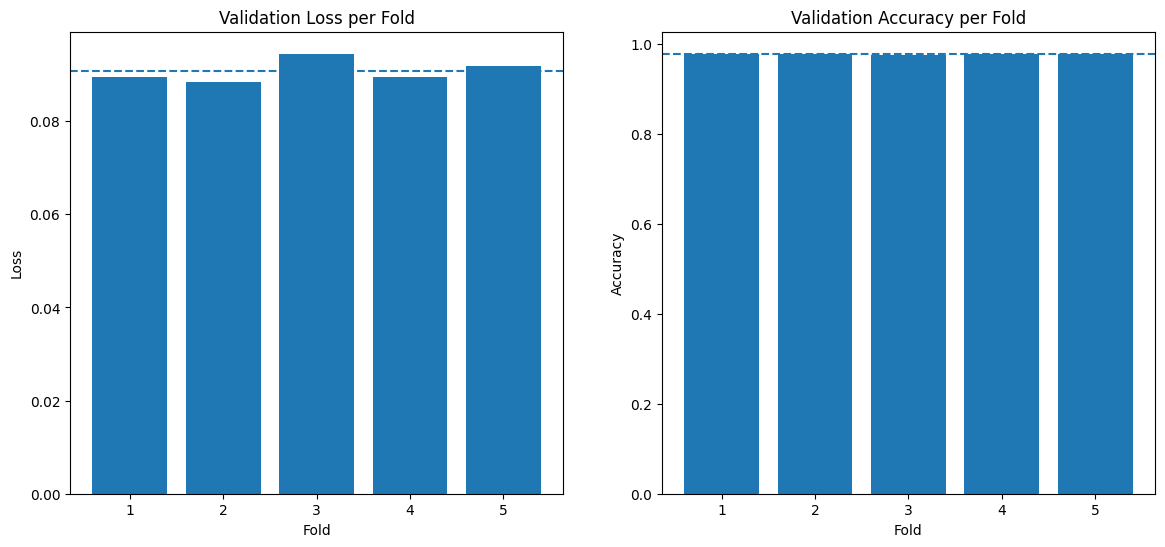


Final Average Accuracy across 5 folds: 0.9765


In [9]:
import numpy as np
# Compute averages
val_losses, val_accuracies = zip(*scores)
average_loss = np.mean(val_losses)
average_accuracy = np.mean(val_accuracies)

print(f"\nK-Fold Results:")
print(f"Average Loss: {average_loss:.4f}")
print(f"Average Accuracy: {average_accuracy:.4f}")

# -------------------------
# BAR CHART PLOTTING
# -------------------------
folds = np.arange(1, k + 1)

plt.figure(figsize=(14, 6))

# Loss plot
plt.subplot(1, 2, 1)
plt.bar(folds, val_losses)
plt.axhline(y=average_loss, linestyle='--')
plt.title('Validation Loss per Fold')
plt.xlabel('Fold')
plt.ylabel('Loss')

# Accuracy plot
plt.subplot(1, 2, 2)
plt.bar(folds, val_accuracies)
plt.axhline(y=average_accuracy, linestyle='--')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Fold')
plt.ylabel('Accuracy')

plt.show()

# Final clean print
print(f"\nFinal Average Accuracy across {k} folds: {average_accuracy:.4f}")